# How do company size, legal structure and owner qualification relate to the distribution and concentration of declared capital among Brazilian companies?

## 1. Data cleaning and summary

The dataset contains Brazilian companies, with one row per company, identified by a unique "company_id". Our main variable of interest is "capital_stock"(declared capital). We compare it across "company_size", "legal_nature" and "owner_qualification".

In [34]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
companies = pd.read_csv("../data/companies.csv")
print(companies.shape)
print("missing values:", companies.isna().sum().sum())
print("duplicate IDs:", companies["company_id"].duplicated().sum())
print("capital stock less than or equal to 0:", (companies["capital_stock"]<= 0).sum())
companies.head()


(141332, 6)
missing values: 0
duplicate IDs: 0
capital stock less than or equal to 0: 0


,company_id,company_name,legal_nature,owner_qualification,capital_stock,company_size
0,41273639,MH MATERIAIS DE CONSTRUCAO LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1000000.0,small-enterprise
1,41274138,CLINICA ESTETICA CAXIAS DO SUL RS LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,200000.0,micro-enterprise
2,41274505,G P CONSTRUCOES E SERVICOS LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,500000.0,small-enterprise
3,41274745,UNICREDIT BANK SAO PAULO CONSULTORIA UNIPESSOA...,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,159600.0,small-enterprise
4,41274856,PRODUCON PRODUTOS PARA CONSTRUCAO LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,200000.0,micro-enterprise


In [9]:
# strip whitespace in text columns
for col in ["company_name", "legal_nature", "owner_qualification", "company_size"]:
    companies[col] = companies[col].str.strip()

- **Whitespace:** We stripped leading and trailing whitespace from all text columns.

### Extreme values

Declared capital is extremely right-skewed, so we first look at the largest observations. We define the top group as companies with capital **strictly above** the 99th percentile. Because the percentile is interpolated and many firms share identical round values, we check how ties behave at the cutoff.

In [14]:
# 99th percentile of capital
p99 = companies["capital_stock"].quantile(0.99)
print("99th percentile:", p99)
n_above = (companies["capital_stock"] > p99).sum()
n_at_or_above = (companies["capital_stock"] >= p99).sum()
n_equal = (companies["capital_stock"] == p99).sum()
print(n_above, "companies strictly above the cutoff")
print(n_at_or_above, "companies at or above cutoff")
print(n_equal, "companies exactly equal to cutoff")

counts = companies["capital_stock"].value_counts()
print(f"most common capital value: {counts.index[0]} (shared by {counts.iloc[0]} firms)")

99th percentile: 207262732.90840003
1414 companies strictly above the cutoff
1414 companies at or above cutoff
0 companies exactly equal to cutoff
most common capital value: 200000.0 (shared by 26858 firms)


Since no company equals the cutoff, `>` and `>=` select the same firms and ties at the boundary are not an issue.

Next we describe the top group: which values repeat, and whether they cluster in particular legal natures or sizes.

In [17]:
top = companies[companies["capital_stock"] > p99]

# values that repeat within the top group
rep = top.groupby("capital_stock").agg(n_firms=("company_id", "size"),
                                        n_legal_natures=("legal_nature", "nunique"),
                                        n_sizes=("company_size", "nunique")).sort_values("n_firms", ascending=False)
rep["share_of_top_group_firms"] = rep["n_firms"] / len(top)
rep["share_of_top_group_capital"] = (rep.index * rep["n_firms"]) / top["capital_stock"].sum()
print("distinct capital values in top group:", top["capital_stock"].nunique(), "of", len(top), "firms")
rep.head()

distinct capital values in top group: 628 of 1414 firms


,n_firms,n_legal_natures,n_sizes,share_of_top_group_firms,share_of_top_group_capital
capital_stock,,,,,
5.000000e+08,416,4,3,0.294201,0.004193
1.000000e+11,184,1,2,0.130127,0.370949
6.000000e+08,40,2,3,0.028289,0.000484
2.000000e+10,26,1,2,0.018388,0.010483
1.000000e+12,23,1,2,0.016266,0.463686


In [19]:
# the ten largest declared values
top.sort_values("capital_stock", ascending=False).head(10)

,company_id,company_name,legal_nature,owner_qualification,capital_stock,company_size
26718,46051969,46.051.969 LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,small-enterprise
48572,49795389,49.795.389 LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,small-enterprise
14440,43845995,SILVINO & COELHO INCORPORACOES E PARTICIPACOES...,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,other
14752,43900640,PEDRO & COELHO INCORPORACOES FUSOES AQUISICOES...,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,other
15561,44038741,COELHO INCORPORACOES E PARTICIPACOES LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,other
15601,44045849,SILVINO INCOPORACOES E PARTICIPACOES LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,other
49208,49896735,HOLDINGS WARE LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,other
49198,49896027,HOLDINGS FOCUS LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,other
49079,49882298,TRUERISE HOLDINGS LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,other
49070,49880645,TRUEWARE HOLDINGS LTDA,Limited Liability Business Company (LLC),Managing Partner / Partner-Administrator,1.000000e+12,other


### Potentially anomalous values

A handful of very round figures (e.g. R$100 billion, R$20 billion, R$1 trillion) are each declared by many firms in the top group, which is unusual for amounts at this scale. We describe these as **potentially anomalous observations**. We do not conclude that they are placeholders as some very large firms may genuinely hold large capital. 

Because we cannot separate genuine large values from anomalous ones, we do not delete them. Instead, we flag them and check how sensitive each result is to their treatment.

In [20]:
# flag the top 1% of companies by capital (kept in the data, not deleted)
companies["top1pct"] = companies["capital_stock"] > p99

# capped version: values above the 99th percentile are set to the cutoff
companies["capital_capped"] = np.where(companies["capital_stock"] > p99, p99, companies["capital_stock"])

# trimmed version: drop the flagged firms
trimmed = companies[~companies["top1pct"]]

print(companies["top1pct"].sum(), "companies flagged")
print("rows in capped:", len(companies), "| rows in trimmed:", len(trimmed))

1414 companies flagged
rows in capped: 141332 | rows in trimmed: 139918


### Sensitivity of summary statistics to the treatment of extreme values

In [22]:
sens = pd.DataFrame({
    "full": companies["capital_stock"].describe(),
    "capped": companies["capital_capped"].describe(),
    "trimmed": trimmed["capital_stock"].describe(),
}).T
sens

,count,mean,std,min,25%,50%,75%,max
full,141332.0,3.536970e+08,1.464616e+10,150000.09,210000.0,400000.0,1000000.0,1.000000e+12
capped,141332.0,4.806034e+06,2.405427e+07,150000.09,210000.0,400000.0,1000000.0,2.072627e+08
trimmed,139918.0,2.760023e+06,1.288556e+07,150000.09,210000.0,400000.0,1000000.0,2.072589e+08


The median is almost unchanged across the three versions (R$400,000 in the full data), whereas the mean falls sharply once extreme values are capped or removed. The full-data mean of about R$354 million is almost 900 times the median, so the mean is not a useful measure of a typical firm here. Medians are therefore preferred for comparisons, with means reported only alongside the sensitivity check above.

### Concentration of declared capital

We measure the share of total capital held by the top group, and check how this share depends on the cutoff chosen and on capping.

In [24]:
total_full = companies["capital_stock"].sum()

rows = []
for q in [0.90, 0.95, 0.99, 0.999]:
    cut = companies["capital_stock"].quantile(q)
    g = companies[companies["capital_stock"] > cut]
    rows.append({"percentile cutoff": q, "firms in top group": len(g),
                 "share of total capital": g["capital_stock"].sum() / total_full})
conc = pd.DataFrame(rows)
display(conc)

# the same top 1% after capping: each firm contributes at most the cutoff
capped_share = (companies.loc[companies["top1pct"], "capital_capped"].sum()
                / companies["capital_capped"].sum())
print(f"top-1% share, full data:   {companies.loc[companies["top1pct"], "capital_stock"].sum() / total_full}")
print(f"top-1% share, capped data: {capped_share}")

,percentile cutoff,firms in top group,share of total capital
0,0.900,14134,0.998409
1,0.950,7067,0.997514
2,0.990,1414,0.992275
3,0.999,33,0.588809


top-1% share, full data:   0.9922747185532392
top-1% share, capped data: 0.4314627479966693


In the full data, the top 1% of companies (1414 firms) account for about 99.2% of declared capital. This figure should be read with care for two reasons: (1) it is calculated on declared capital, which we cannot verify, and (2) it is driven by a small number of repeated, potentially anomalous values in the top group. When the same firms are capped at the 99th-percentile cutoff, their share of total capital falls to the value shown above, which is far lower. The top 1% hold about 99% of capital only if all the extreme declared values are taken at face value; if they are excluded or limited, concentration is still present but much less extreme. The 99% figure should therefore be presented together with the capped figure.

### Company size and capital

In [33]:
by_size = companies.groupby("company_size").agg(n=("capital_stock", "size"),
                                                median_full=("capital_stock", "median"),
                                                median_capped=("capital_capped", "median"),
                                                mean_full=("capital_stock", "mean"),
                                                mean_capped=("capital_capped", "mean"),
                                                n_top1pct=("top1pct", "sum"),
                                                share_in_top1pct=("top1pct", "mean"))
by_size["mean_trimmed"] = trimmed.groupby("company_size")["capital_stock"].mean()
by_size["median_trimmed"] = trimmed.groupby("company_size")["capital_stock"].median()
by_size.reset_index()

,company_size,n,median_full,median_capped,mean_full,mean_capped,n_top1pct,share_in_top1pct,mean_trimmed,median_trimmed
0,micro-enterprise,66202,300000.0,300000.0,2.129195e+07,2.248587e+06,240,0.003625,1.502651e+06,300000.0
1,other,42520,1037169.0,1037169.0,5.004296e+08,8.536992e+06,594,0.013970,5.721481e+06,1000005.0
2,small-enterprise,32610,350000.0,350000.0,8.371934e+08,5.133166e+06,580,0.017786,1.472999e+06,350000.0


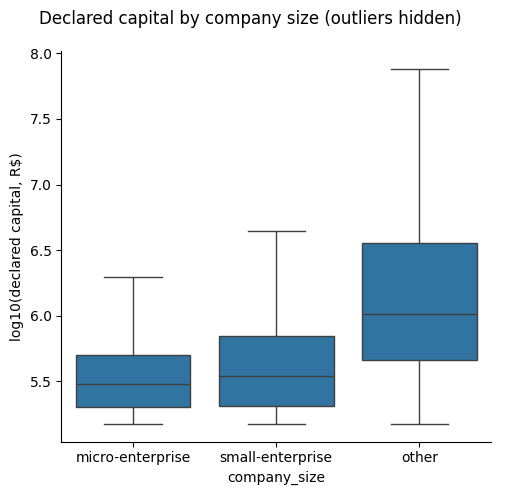

In [37]:
# distribution of log10(capital) by size, full data (log scale because of the skew)
companies["log_capital_stock"] = np.log10(companies["capital_stock"])
order = ["micro-enterprise", "small-enterprise", "other"]
g = sns.catplot(companies, x="company_size", y="log_capital_stock", order=order, kind="box", showfliers=False)

g.set_axis_labels("company_size", "log10(declared capital, R$)")
g.figure.suptitle("Declared capital by company size (outliers hidden)")

plt.tight_layout()
plt.show()

Median capital rises with size: about R$300,000 for micro-enterprises, R$350,000 for small enterprises and R$1.04 million for other. Small enterprises, however, have a higher mean than other in the full data, which is a sign that a few extreme values drive the mean. When capped or trimmed, the capped means drop to R5.13 million for small enterprises, R8.54 million for other, and R2.25 million for micro-enterprises (with trimmed means at R1.47million, R5.72 million, and R$1.50 million, respectively). Furthermore, the "share_in_top1pct" metric shows that extreme values are slightly more concentrated among small enterprises (1.78%) and other (1.40%) than micro-enterprises (0.36%). We compare sizes using medians and treat means as sensitive to the extreme values. These are descriptive associations; they do not show that size causes differences in declared capital. 

### Legal structure and owner qualification
For each category we compare its share of all companies with its share of the top 1%. A ratio above 1 means the category is over-represented among high-capital firms.

In [45]:
def composition(col, min_n=30):
    all = companies[col].value_counts()
    top = companies[companies["top1pct"]][col].value_counts()

    df = pd.DataFrame({"n_all": all, "n_top": top}).fillna(0)

    df["pct_all"] = df["n_all"] / df["n_all"].sum()
    df["pct_top"] = df["n_top"] / df["n_top"].sum()
    df["over_rep"] = df["pct_top"] / df["pct_all"]
    df["pct_in_top"] = df["n_top"] / df["n_all"]
    df["small_category"] = df["n_all"] < min_n

    return df.sort_values("n_top", ascending=False)

comp_legal = composition("legal_nature")
comp_legal.reset_index().head()

,legal_nature,n_all,n_top,pct_all,pct_top,over_rep,pct_in_top,small_category
0,Limited Liability Business Company (LLC),119288,919.0,0.844027,0.649929,0.770034,0.007704,False
1,Privately Held Corporation,2897,236.0,0.020498,0.166902,8.142441,0.081464,False
2,Sole Proprietorship,15209,204.0,0.107612,0.144272,1.340666,0.013413,False
3,Publicly Traded Corporation,52,26.0,0.000368,0.018388,49.975955,0.500000,False
4,State-Owned Enterprise,15,6.0,0.000106,0.004243,39.980764,0.400000,True


In [46]:
comp_owner = composition("owner_qualification")
comp_owner.head(5)

,n_all,n_top,pct_all,pct_top,over_rep,pct_in_top,small_category
owner_qualification,,,,,,,
Managing Partner / Partner-Administrator,107027,734.0,0.757274,0.519095,0.685478,0.006858,False
Entrepreneur / Business Owner,15201,204.0,0.107555,0.144272,1.341372,0.013420,False
Administrator / Manager,15236,193.0,0.107803,0.136492,1.266127,0.012667,False
Director / Officer,1634,175.0,0.011561,0.123762,10.704764,0.107099,False
President / Chair,1343,93.0,0.009502,0.065771,6.921465,0.069248,False


In [40]:
# share of total capital by legal nature, with and without the top 1%
cap_all = companies.groupby("legal_nature")["capital_stock"].sum() / companies["capital_stock"].sum()
cap_trim = trimmed.groupby("legal_nature")["capital_stock"].sum() / trimmed["capital_stock"].sum()
cap_capped = companies.groupby("legal_nature")["capital_capped"].sum() / companies["capital_capped"].sum()

legal = pd.DataFrame({
    "firms_pct": companies["legal_nature"].value_counts(normalize=True),
    "capital_share_full": cap_all,
    "capital_share_capped": cap_capped,
    "capital_share_trimmed": cap_trim,}).sort_values("capital_share_full", ascending=False)
legal.reset_index().head()

,legal_nature,firms_pct,capital_share_full,capital_share_capped,capital_share_trimmed
0,Limited Liability Business Company (LLC),0.844027,0.981718,0.660087,0.667795
1,Privately Held Corporation,0.020498,0.009766,0.143329,0.125439
2,Sole Proprietorship,0.107612,0.003585,0.152528,0.158794
3,Publicly Traded Corporation,0.000368,0.003290,0.009482,0.002724
4,Simple Innovation Company,0.001019,0.000691,0.001690,0.000826


In [42]:
# median capital by category: top group vs all firms (full data)
t = companies[companies["top1pct"]].groupby("legal_nature")["capital_stock"].median().rename("median_top1pct")
a = companies.groupby("legal_nature")["capital_stock"].median().rename("median_all")
pd.concat([t, a], axis=1).sort_values("median_all", ascending=False).reset_index()

,legal_nature,median_top1pct,median_all
0,Publicly Traded Corporation,9.601829e+08,1.997102e+08
1,Partnership Limited by Shares,NaN,1.383254e+08
2,State-Owned Enterprise,3.284121e+08,8.864527e+07
3,Individual Limited Liability Company (Simple),NaN,4.000000e+07
4,Mixed-Capital Company,4.983792e+08,1.700000e+07
5,Privately Held Corporation,5.000007e+08,4.500000e+06
6,Simple General Partnership,NaN,2.630533e+06
7,Brazilian Branch of a Foreign Company,NaN,1.439251e+06
8,Silent Partnership,6.104970e+08,1.350000e+06
9,Simple Limited Partnership,4.797479e+08,5.000000e+05


Limited liability business companies (LLCs) are about 84% of firms and hold about 98.2% of total declared capital in the full data. Once the top 1% is removed, their share drops to about 66.8% and sole proprietorships (15.9%) and privately held corporations (12.5%) become visible, so conclusions about legal structure depend strongly on how extreme values are treated. 

About 75.7% of companies list a Managing Partner / Partner-Administrator as owner qualification, with the rest spread over many small categories, so owner-qualification comparisons for the top group rest on small counts in most categories.

## Summary of findings

- **Skew:** Declared capital is extremely right-skewed. The median firm declares R$400,000, while the mean is about R$354 million.
- **Concentration:** The top 1% (1,414 firms above the 99th percentile, about R$207 million) hold about 99.2% of declared capital in the full data. This depends on a few repeated, potentially anomalous extreme values and on taking declared capital at face value; the capped share is much smaller.
- **Treatment of extreme values:** Medians are stable across the full, capped and trimmed versions; means, totals and shares of capital are not. We report full results as the baseline with capped and trimmed versions as sensitivity checks.
- **Company size:** Median capital increases from micro-enterprises to small enterprises to "other", but the means do not follow the same order because of extreme values. "other" is treated as an undefined residual category.
- **Legal structure:** LLCs dominate both the number of firms and (in the full data) total capital, but their share falls substantially without the top 1%.
- **Owner qualification:** One category dominates by count; most other categories are small.

*Limitations:* declared capital is self-reported, the cutoff at the 99th percentile is a convention rather than a test, and all comparisons are descriptive.

# data visualization

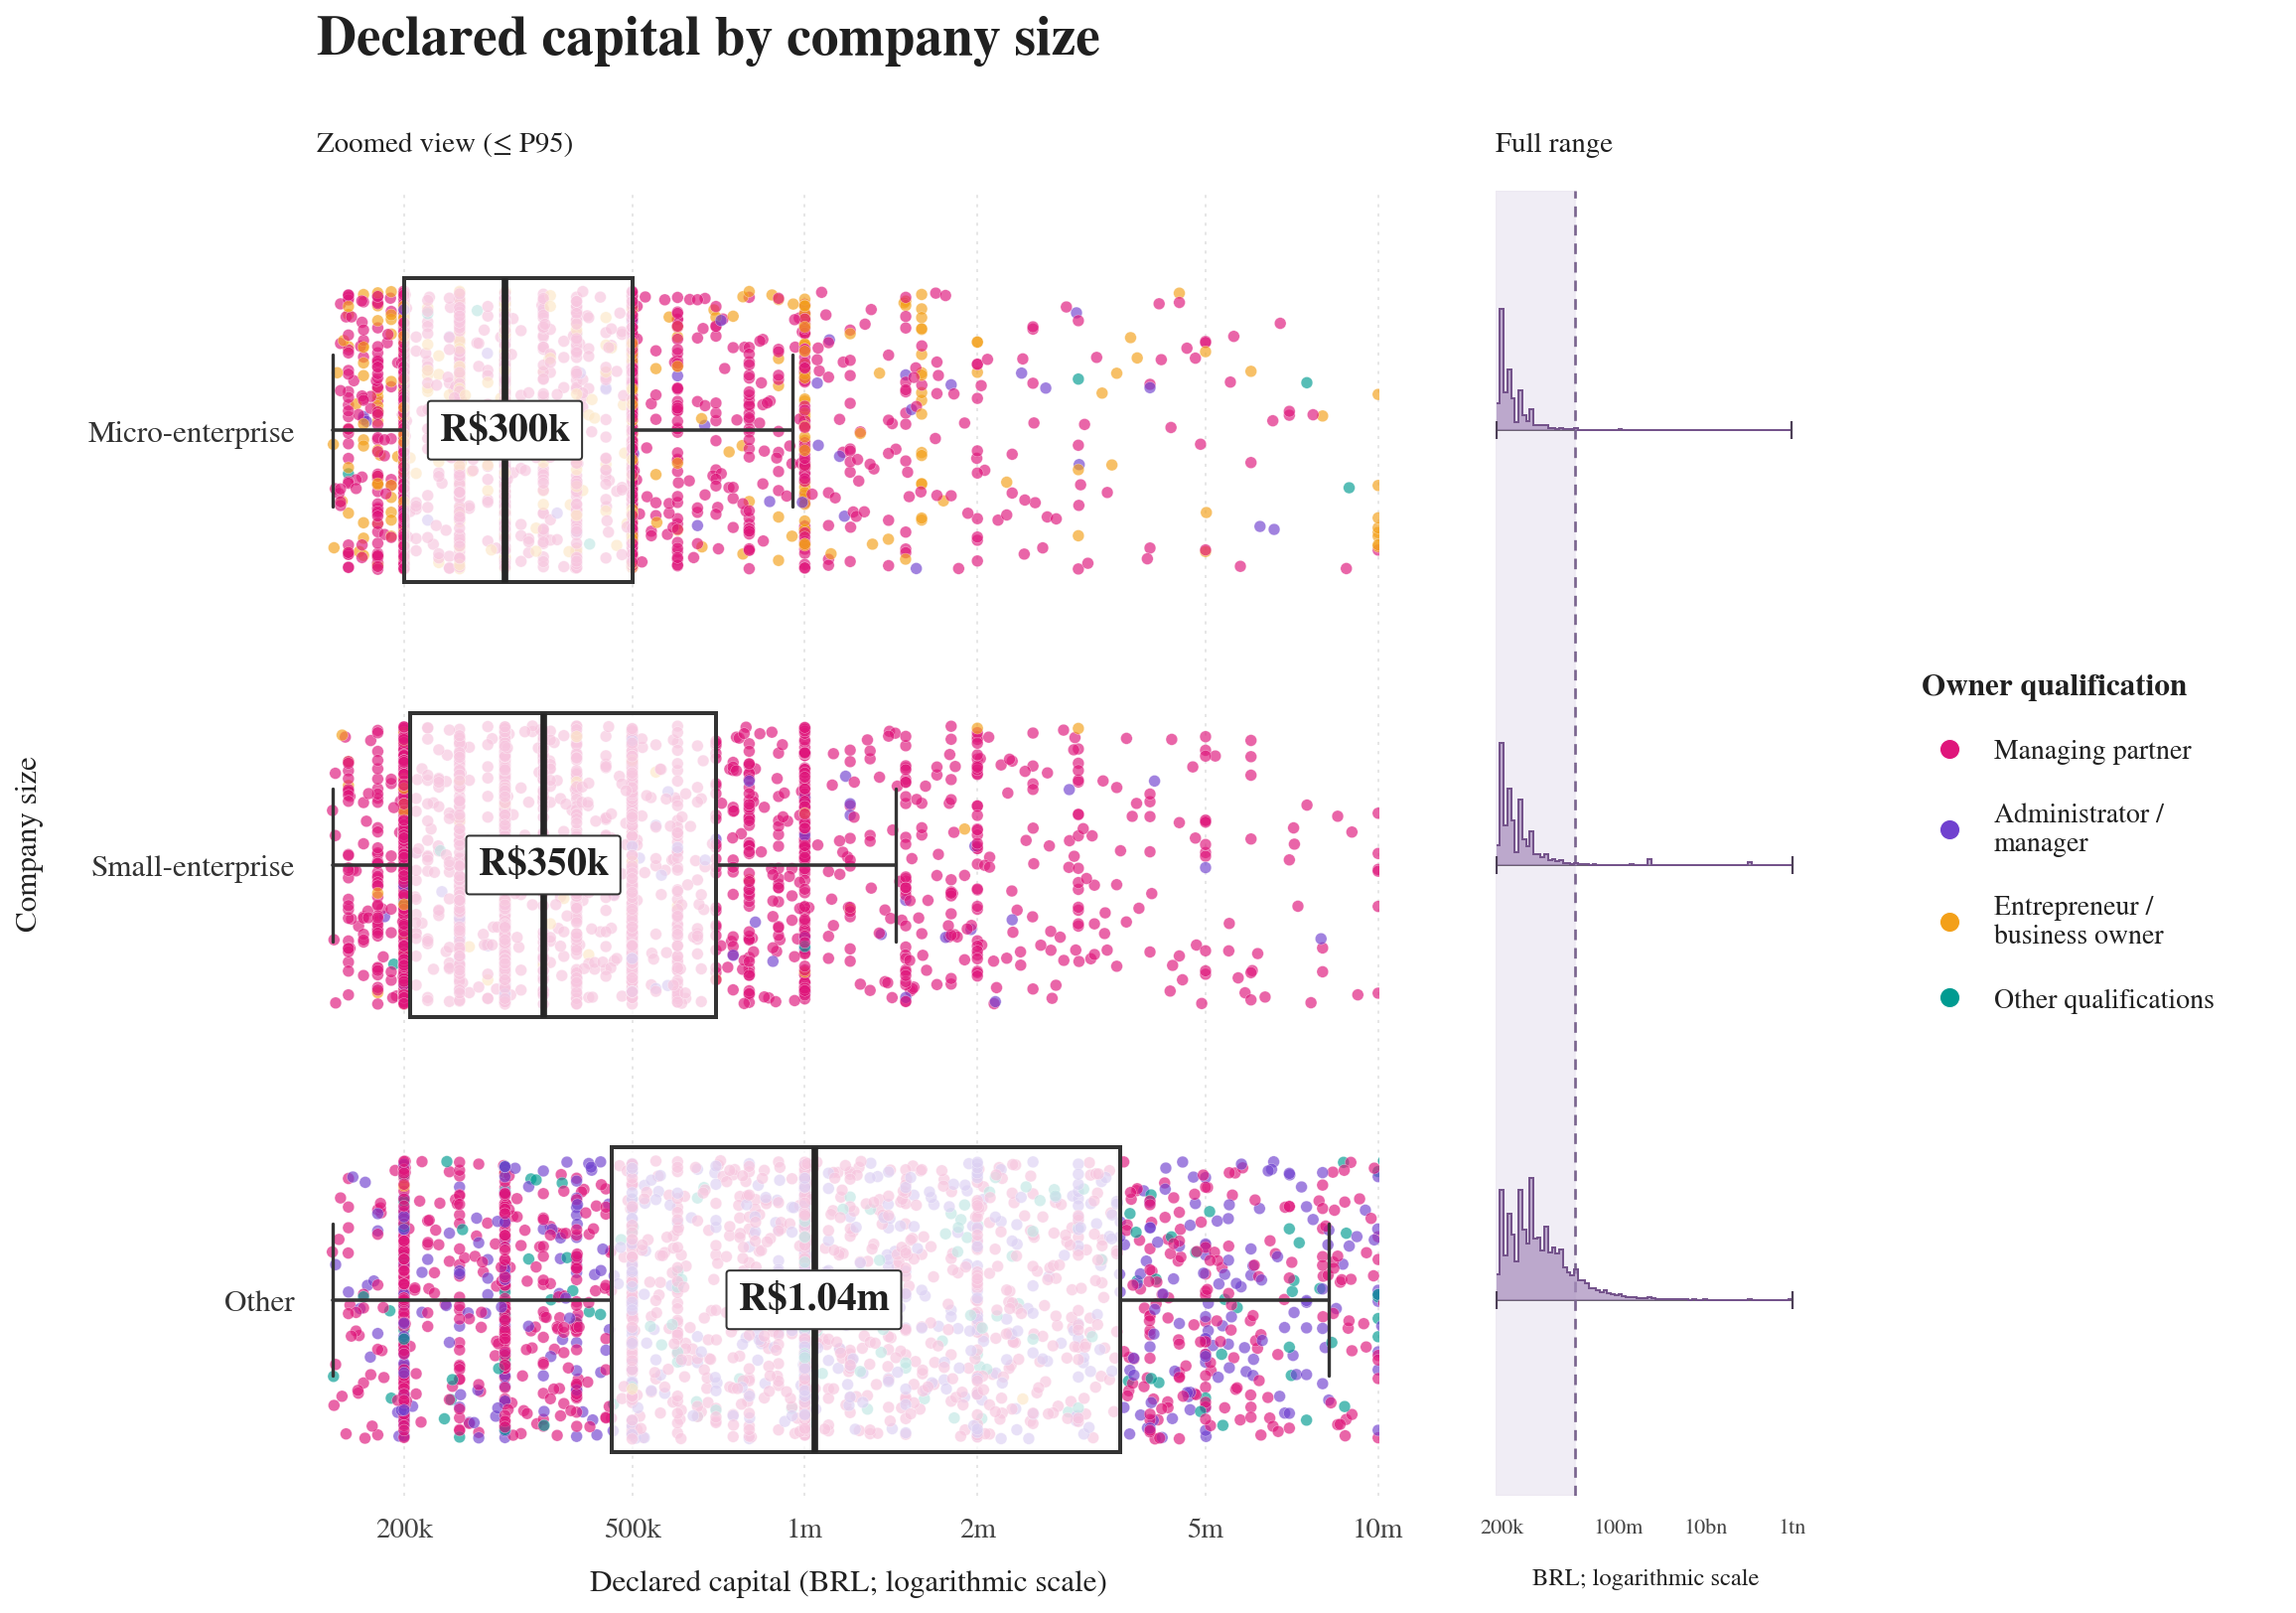

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cbook import boxplot_stats
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

# Reuse the cleaned data; this cell can also run by itself in a fresh kernel.
project_root = next(
    (path for path in [Path.cwd(), Path.cwd().parent]
     if (path / "data" / "companies.csv").is_file()),
    None
)
if "companies" in globals():
    df = companies.copy()
elif project_root is not None:
    df = pd.read_csv(project_root / "data" / "companies.csv")
else:
    raise FileNotFoundError("Run this cell from the project root or src folder.")

for column in ["company_size", "owner_qualification"]:
    df[column] = df[column].str.strip()
if df["capital_stock"].isna().any() or (df["capital_stock"] <= 0).any():
    raise ValueError("Capital must be positive and non-missing for a log-scale plot.")

order = ["micro-enterprise", "small-enterprise", "other"]
size_labels = ["Micro-enterprise", "Small-enterprise", "Other"]
groups = [df.loc[df["company_size"] == size, "capital_stock"].to_numpy()
          for size in order]
boxes = boxplot_stats(groups, whis=1.5)
view_limit = df["capital_stock"].quantile(0.95)
view_min = df["capital_stock"].min() * 0.94
full_max = df["capital_stock"].max() * 1.18

# Colour adds information: points show owner qualification, rather than repeating size.
role_names = df["owner_qualification"].value_counts().head(3).index.tolist()
role_order = role_names + ["Other qualifications"]
role_colours = dict(zip(role_order, ["#DF167B", "#7041CF", "#F3A019", "#009B91"]))
short_roles = {
    "Managing Partner / Partner-Administrator": "Managing partner",
    "Administrator / Manager": "Administrator /\nmanager",
    "Entrepreneur / Business Owner": "Entrepreneur /\nbusiness owner",
    "Other qualifications": "Other qualifications",
}
df["plot_role"] = df["owner_qualification"].where(
    df["owner_qualification"].isin(role_names), "Other qualifications"
)

# Equal random samples per size show composition; full counts are given in the Markdown below.
points_per_size = 2500
point_parts = [
    df.loc[df["company_size"] == size].sample(
        n=min(points_per_size, (df["company_size"] == size).sum()),
        random_state=42 + index
    )
    for index, size in enumerate(order)
]
plot_df = pd.concat(point_parts).sample(frac=1, random_state=42)
rng = np.random.default_rng(42)
point_y = plot_df["company_size"].map(dict(zip(order, range(len(order))))).to_numpy()
point_y = point_y + rng.uniform(-0.32, 0.32, len(plot_df))


def brl_short(value, position=None):
    if value >= 1e12:
        return f"{value / 1e12:g}tn"
    if value >= 1e9:
        return f"{value / 1e9:g}bn"
    if value >= 1e6:
        return f"{value / 1e6:g}m"
    return f"{value / 1e3:g}k"


# Serif titles, stronger dots and white box fills follow the reference's visual style.
with plt.rc_context({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "font.size": 12,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "text.color": "#202020",
    "axes.labelcolor": "#202020",
    "xtick.color": "#454545",
    "ytick.color": "#333333",
    "pdf.fonttype": 42,
}):
    fig = plt.figure(figsize=(14.8, 10.8), dpi=160)
    grid = fig.add_gridspec(
        1, 3, width_ratios=[4.6, 1.3, 1.6],
        left=0.15, right=0.985, bottom=0.10, top=0.86, wspace=0.20
    )
    ax = fig.add_subplot(grid[0, 0])
    overview = fig.add_subplot(grid[0, 1], sharey=ax)
    legend_axis = fig.add_subplot(grid[0, 2])
    legend_axis.set_axis_off()

    # Scatter values are not jittered horizontally, so repeated capital amounts stay visible.
    ax.scatter(
        plot_df["capital_stock"], point_y,
        c=plot_df["plot_role"].map(role_colours),
        s=28, alpha=0.66, edgecolors="#FFFFFF", linewidths=0.18,
        rasterized=True, zorder=2
    )

    # Compute all box statistics in original BRL, and only then set the log display scale.
    ax.bxp(
        boxes, positions=np.arange(len(order)), vert=False, widths=0.70,
        showfliers=False, patch_artist=True, manage_ticks=False,
        boxprops={"facecolor": (1, 1, 1, 0.76), "edgecolor": "#333333", "linewidth": 1.8},
        medianprops={"color": "#252525", "linewidth": 3},
        whiskerprops={"color": "#333333", "linewidth": 1.6},
        capprops={"color": "#333333", "linewidth": 1.5}, zorder=3
    )
    for index, box in enumerate(boxes):
        median = box["med"]
        median_label = f"R${median / 1e3:,.0f}k" if median < 1e6 else f"R${median / 1e6:.2f}m"
        ax.text(
            median, index, median_label,
            ha="center", va="center", fontsize=18, fontweight="bold", zorder=5,
            bbox={"boxstyle": "round,pad=0.30,rounding_size=0.08",
                  "facecolor": "white", "edgecolor": "#333333", "linewidth": 0.9}
        )
        if box["whishi"] > view_limit:
            ax.plot(view_limit, index, marker=">", color="#333333", clip_on=False, zorder=6)

    ax.set_xscale("log")
    ax.set_xlim(view_min, view_limit)
    ax.set_ylim(len(order) - 0.55, -0.55)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(size_labels, fontsize=14)
    ax.xaxis.set_major_locator(FixedLocator([2e5, 5e5, 1e6, 2e6, 5e6, 1e7]))
    ax.xaxis.set_major_formatter(FuncFormatter(brl_short))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("Declared capital (BRL; logarithmic scale)", fontsize=14, labelpad=12)
    ax.set_ylabel("Company size", fontsize=14, labelpad=20)
    ax.set_title("Zoomed view (≤ P95)", loc="left", fontsize=13, pad=18)
    ax.grid(axis="x", color="#DFDFDF", linewidth=0.7, linestyle=(0, (2, 4)), zorder=0)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="both", length=0, pad=10)
    ax.tick_params(axis="x", labelsize=13)

    # Complete-data histograms keep the entire upper tail in view, including true maxima.
    # A shared log-bin grid is used; heights are scaled within each size group.
    log_edges = np.geomspace(df["capital_stock"].min(), df["capital_stock"].max(), 81)
    overview.axvspan(view_min, view_limit, color="#ECE8F2", alpha=0.75, zorder=0)
    overview.axvline(view_limit, color="#79648E", linewidth=1.2, linestyle=(0, (4, 3)))
    for index, values in enumerate(groups):
        counts, edges = np.histogram(values, bins=log_edges)
        height = counts / counts.max() * 0.28
        overview.stairs(index - height, edges, baseline=index,
                        fill=True, color="#A88EBD", alpha=0.72, linewidth=0, zorder=2)
        overview.stairs(index - height, edges, baseline=None,
                        color="#74538B", linewidth=0.9, zorder=3)
        overview.hlines(index, values.min(), values.max(), color="#6D6375", linewidth=0.9, zorder=1)
        overview.plot([values.min(), values.max()], [index, index],
                      linestyle="none", marker="|", markersize=8, color="#4D4057", zorder=4)
    overview.set_xscale("log")
    overview.set_xlim(view_min, full_max)
    overview.xaxis.set_major_locator(FixedLocator([2e5, 1e8, 1e10, 1e12]))
    overview.xaxis.set_major_formatter(FuncFormatter(brl_short))
    overview.xaxis.set_minor_locator(NullLocator())
    overview.tick_params(axis="y", left=False, labelleft=False)
    overview.tick_params(axis="x", length=0, pad=10, labelsize=10)
    overview.set_title("Full range", loc="left", fontsize=13, pad=18)
    overview.set_xlabel("BRL; logarithmic scale", fontsize=11, labelpad=14)
    overview.grid(False)

    for plot_axis in [ax, overview]:
        for spine in plot_axis.spines.values():
            spine.set_visible(False)

    fig.text(0.15, 0.94, "Declared capital by company size",
             fontsize=25, fontweight="bold", ha="left")

    handles = [
        Line2D([], [], marker="o", linestyle="none", markersize=9,
               markerfacecolor=role_colours[role], markeredgecolor="white",
               markeredgewidth=0.4, label=short_roles.get(role, role))
        for role in role_order
    ]
    # A dedicated right-hand axis keeps the legend visible in notebook and exports.
    legend = legend_axis.legend(
        handles=handles, title="Owner qualification", title_fontsize=14,
        loc="center left", ncol=1, frameon=False, fontsize=12.5,
        handletextpad=0.6, labelspacing=1.4, borderaxespad=0,
        alignment="left"
    )
    legend.get_title().set_fontweight("bold")

    if project_root is not None:
        output_dir = project_root / "outputs" / "visualisation-preview"
        output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_dir / "company_size_box_strip.png", dpi=180, facecolor="white", bbox_inches="tight", pad_inches=0.22)
        fig.savefig(output_dir / "company_size_box_strip.pdf", dpi=180, facecolor="white", bbox_inches="tight", pad_inches=0.22)
    plt.show()


### Interpretation

Median declared capital is R$300,000 for micro-enterprises, R$350,000 for small enterprises and approximately R$1.04 million for the `other` category. The micro- and small-enterprise distributions overlap substantially. The `other` category has a higher median and a wider middle 50% of capital values. Its meaning is undefined in the supplied data, so it should not automatically be interpreted as large companies.

The full-range overview shows long upper tails in all three groups. Medians therefore provide a useful summary of typical capital alongside the distributions. These are descriptive associations within the supplied sample, rather than causal effects.

### Figure notes

- **Boxplots:** All 141,332 companies contribute to the statistics. Boxes show Q1–Q3, with the median labelled; whiskers extend to the most extreme observations within 1.5 times the interquartile range. Separate boxplot outlier symbols are hidden. Statistics are calculated in original BRL, then displayed on logarithmic axes.
- **Zoom:** The left panel ends at the overall 95th percentile, R$10,057,846.55 (about R$10.06 million). This is a viewing limit: capital values are neither deleted nor capped. The percentage beyond this limit differs by size, as shown below.
- **Points and colours:** Up to 2,500 companies are randomly sampled within each size group, with a fixed seed. Points show the three most common owner qualifications plus an aggregated category for the remaining qualifications. “Managing partner” abbreviates “Managing Partner / Partner-Administrator”. Sampled point counts should not be used to compare group sizes; points above the left-panel limit lie outside that panel's view.
- **Full-range overview:** Histograms use all records and common logarithmic bins. Their heights are scaled to each group's own peak, so heights do not compare company counts across groups. Horizontal endpoints mark the observed minimum and maximum; shading corresponds to the left panel's viewing range.

| Company size | All companies | Above the main-view limit |
|---|---:|---:|
| Micro-enterprise | 66,202 | 1.71% |
| Small-enterprise | 32,610 | 2.92% |
| Other | 42,520 | 11.71% |

The source sample contains only companies with declared capital above R$150,000. Capital is declared rather than independently verified; unusually large values are not automatically treated as errors.
